# 1. Imports and config

In [2]:
import sys
sys.path.append("..")   # so we can import from src/

import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src.config import *

random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Train dir exists:", TRAIN_DIR.exists())

Train dir exists: True


# 2.Number of categories and images per class

In [3]:
def list_images(folder):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]

rows = []
for split, path in {"train": TRAIN_DIR, "valid": VALID_DIR, "test": TEST_DIR}.items():
    for cls in CLASS_NAMES:
        rows.append({"split": split, "class": cls, "count": len(list_images(path / cls))})

df_counts = pd.DataFrame(rows)
pivot = df_counts.pivot(index="class", columns="split", values="count")[["train", "valid", "test"]]
pivot["total"] = pivot.sum(axis=1)
display(pivot)
print("\nTotal images per split:\n", pivot[["train", "valid", "test", "total"]].sum())
print("\nNumber of classes:", NUM_CLASSES, "->", CLASS_NAMES)

split,train,valid,test,total
class,,,,
glioma,564,161,80,805
meningioma,358,124,63,545
no_tumor,335,99,49,483
pituitary,438,118,54,610



Total images per split:
 split
train    1695
valid     502
test      246
total    2443
dtype: int64

Number of classes: 4 -> ['glioma', 'meningioma', 'no_tumor', 'pituitary']


# 3.Class distribution plot

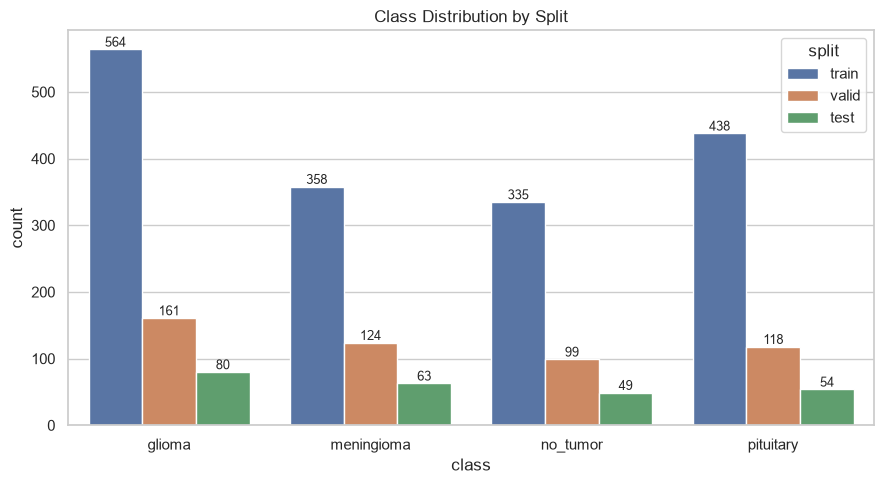

In [4]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_counts, x="class", y="count", hue="split")
for c in ax.containers:
    ax.bar_label(c, fontsize=9)
plt.title("Class Distribution by Split")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_class_distribution.png", dpi=150)
plt.show()

# 4.Class imbalance check and class weights

In [5]:
train_counts = pivot["train"]
print((train_counts / train_counts.sum() * 100).round(1).astype(str) + " %")
print("\nImbalance ratio (max/min):", round(train_counts.max() / train_counts.min(), 2))

# Class weights (used later during training): total / (n_classes * count)
class_weights = {
    i: train_counts.sum() / (NUM_CLASSES * train_counts[cls])
    for i, cls in enumerate(CLASS_NAMES)
}
print("\nClass weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in class_weights.items()})

class
glioma        33.3 %
meningioma    21.1 %
no_tumor      19.8 %
pituitary     25.8 %
Name: train, dtype: str

Imbalance ratio (max/min): 1.68

Class weights: {'glioma': np.float64(0.751), 'meningioma': np.float64(1.184), 'no_tumor': np.float64(1.265), 'pituitary': np.float64(0.967)}


# 5.Sample images from each class

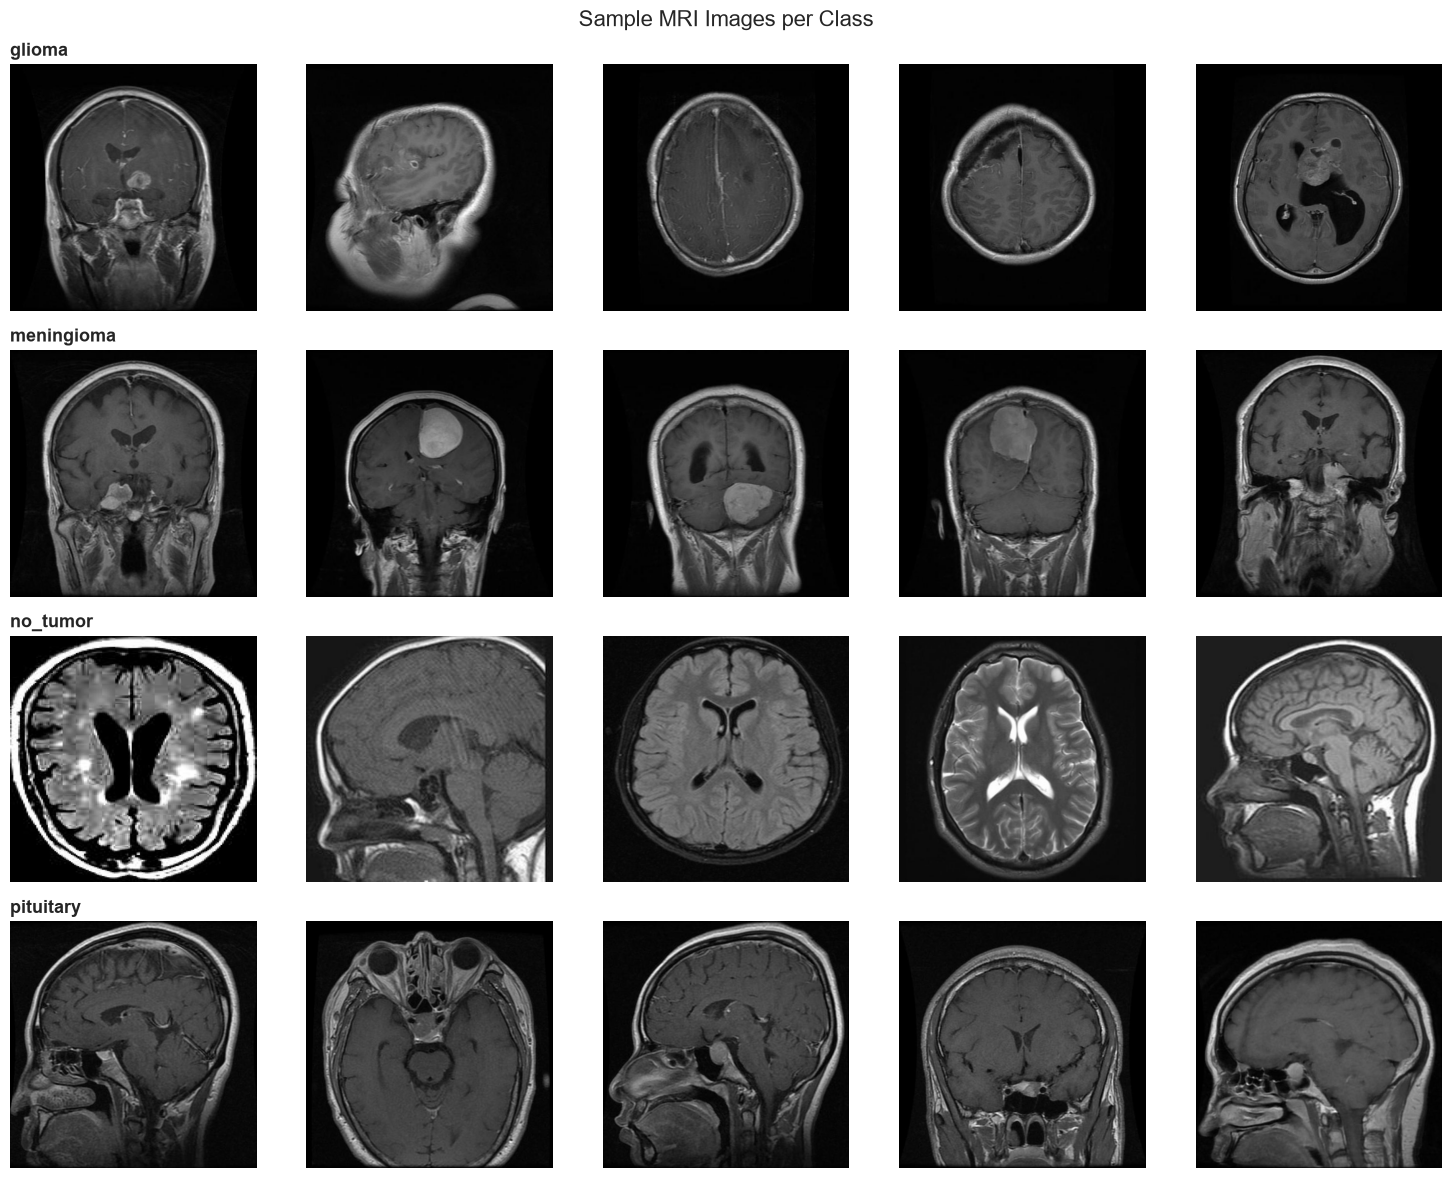

In [6]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(15, 12))
for r, cls in enumerate(CLASS_NAMES):
    imgs = random.sample(list_images(TRAIN_DIR / cls), 5)
    for c, p in enumerate(imgs):
        axes[r, c].imshow(Image.open(p))
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=13, fontweight="bold")
plt.suptitle("Sample MRI Images per Class", fontsize=16)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_sample_images.png", dpi=150)
plt.show()

# 6:Image resolution and channel consistency

In [9]:
size_counter, mode_counter = Counter(), Counter()
for split_dir in [TRAIN_DIR, VALID_DIR, TEST_DIR]:
    for cls in CLASS_NAMES:
        for p in list_images(split_dir / cls):
            with Image.open(p) as im:      # reads header only, so it's fast
                size_counter[im.size] += 1
                mode_counter[im.mode] += 1

print("Image sizes (W, H):", dict(size_counter))
print("Color modes:", dict(mode_counter))

Image sizes (W, H): {(640, 640): 2443}
Color modes: {'RGB': 2443}


# 7: Pixel intensity distribution

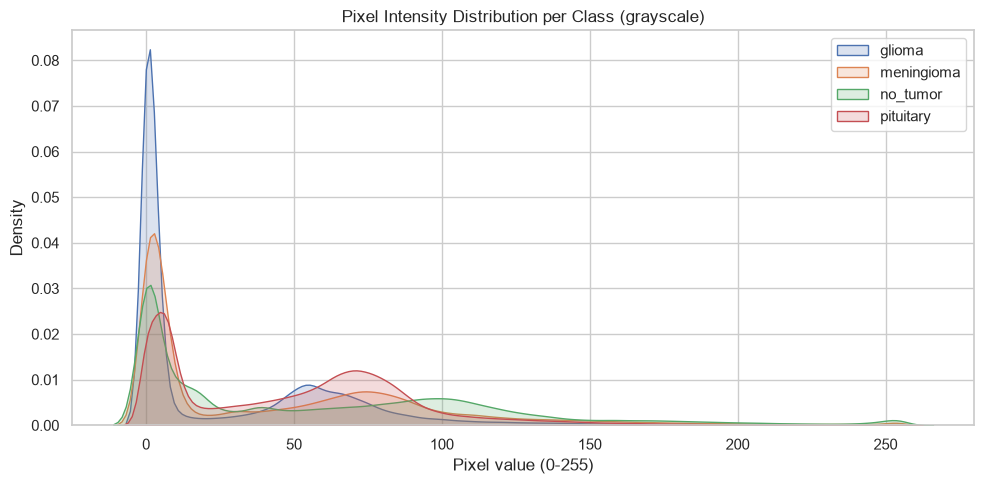

In [10]:
plt.figure(figsize=(10, 5))
for cls in CLASS_NAMES:
    sample = random.sample(list_images(TRAIN_DIR / cls), 60)
    pixels = np.concatenate([np.array(Image.open(p).convert("L")).ravel()[::20] for p in sample])
    sns.kdeplot(pixels, label=cls, fill=True, alpha=0.2)
plt.title("Pixel Intensity Distribution per Class (grayscale)")
plt.xlabel("Pixel value (0-255)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_pixel_intensity.png", dpi=150)
plt.show()

## Observations
- Number of classes: 4 -> ['glioma', 'meningioma', 'no_tumor', 'pituitary']

- Split sizes (train/valid/test): 1695,502,246

- Class imbalance (which class is largest/smallest, ratio): 1.68 ,Glioma=33.3%, no_tumor=19.8%

- Image resolution / channels: Image sizes (W, H): {(640, 640): 2443}
                               Color modes: {'RGB': 2443}

- Visual differences between classes: 

- Decision: use class weights + augmentation, resize to 224x224, normalize to 0-1